# 03. Segmentación clásica del ventrículo lateral

Pipeline final, solo técnicas clásicas (umbral, filtros, morfología, watershed, condicionales).

**Preprocesamiento**
1. Recorte a la cabeza
2. Máscara cerebral: Otsu, erosión, componente mayor, dilatación, cierre, relleno en 3 planos
3. Corrección de inhomogeneidad (filtrado homomórfico: log, pasabajo gaussiano sobre tejido, resta)
4. Normalización por percentiles dentro del cerebro
5. Filtro de mediana (ruido sal y pimienta)

**Segmentación**
6. LCR: Otsu de 3 clases
7. LCR encerrado (descarta lo que toca el borde cerebral)
8. Condicional: si está contaminado por surcos, rama de ventrículos pequeños (ROI central, sin línea media, black top-hat, pareja izq/der)
9. Limpieza y regla de áreas (1 área o par parecido)
10. Watershed de relleno sobre el gradiente
11. Forma uniforme (cierre, relleno en 3 planos)
12. Quitar línea media solo debajo de los laterales (apertura por reconstrucción)

In [ ]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu, threshold_multiotsu
from skimage.segmentation import watershed

from src.io import list_scans, load, load_seg
from src.paths import OUTPUTS

FIG_DIR = OUTPUTS / "figuras_03"
if FIG_DIR.exists():
    shutil.rmtree(FIG_DIR)
FIG_DIR.mkdir(parents=True)

def guardar(nombre, dpi=110):
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

def dice(a, b):
    d = a.sum() + b.sum()
    return 2 * (a & b).sum() / d if d else np.nan

scans = list_scans()
ball = ndi.generate_binary_structure(3, 1)
N_CASOS = 8

## Parámetros

In [ ]:
EROSION = 8
BIAS = True
BIAS_SIGMA_MM = 25
MEDIAN = 3

RIM = 3
OPEN_ENC = 1
MIN_ML = 0.5
BIG_ML = 40
MAX_DIST = 45
RATIO = 3

ROI_X_MM, ROI_Y_MM = 35, 45
ROI_ZDOWN_MM, ROI_ZUP_MM = 10, 40
MID_MM = 2
TOPHAT_MM = 4

MIN_FINAL_ML = 0.5
MIN_FRAC = 0.05
PAIR_SIM = 0.4

T_MID = 0.3
WS_FAR_MM = 10
SIGMA_WS = 1.0
CLOSE_ITER = 2

EROS_REC = 2
MID_REC_MM = 5
Z_OFF_MM = 0
MAX_LOSS = 0.7

## Preprocesamiento

In [ ]:
def crop_box(img, pad=6):
    head = img > threshold_otsu(img[img > 0])
    idx = np.where(head)
    return tuple(slice(max(i.min() - pad, 0), i.max() + pad + 1) for i in idx)


def rellenar_3planos(m):
    m = m.copy()
    for axis in range(3):
        for i in range(m.shape[axis]):
            sl = [slice(None)] * 3
            sl[axis] = i
            m[tuple(sl)] = ndi.binary_fill_holes(m[tuple(sl)])
    return m


def brain_mask(img):
    head = img > threshold_otsu(img[img > 0])
    eroded = ndi.binary_erosion(head, ball, iterations=EROSION)
    lab, n = ndi.label(eroded)
    largest = lab == (np.argmax(ndi.sum(eroded, lab, range(1, n + 1))) + 1)
    brain = ndi.binary_dilation(largest, ball, iterations=EROSION) & head
    brain = ndi.binary_closing(brain, ball, iterations=3)
    return rellenar_3planos(ndi.binary_fill_holes(brain))


def corregir_sesgo(img, brain, zooms):
    tejido = brain & (img > threshold_otsu(img[brain]))
    logi = np.log1p(np.clip(img, 0, None))
    s = [BIAS_SIGMA_MM / z for z in zooms]
    num = ndi.gaussian_filter(logi * tejido, s)
    den = ndi.gaussian_filter(tejido.astype(float), s)
    bias = np.where(den > 1e-3, num / np.maximum(den, 1e-3), 0)
    ref = logi[tejido].mean()
    corr = np.expm1(logi - bias + ref) * brain
    return corr, np.exp(bias - ref) * brain


def preprocesar_sin_sesgo(img, zooms):
    global BIAS
    prev, BIAS = BIAS, False
    out = preprocesar(img, zooms)
    BIAS = prev
    return out


def preprocesar(img, zooms):
    brain = brain_mask(img)
    if BIAS:
        corr, campo = corregir_sesgo(img, brain, zooms)
    else:
        corr, campo = img * brain, np.ones_like(img) * brain
    lo, hi = np.percentile(corr[brain], [1, 99])
    norm = np.clip((corr - lo) / (hi - lo), 0, 1) * brain
    if MEDIAN:
        norm = ndi.median_filter(norm, size=MEDIAN) * brain
    t3 = threshold_multiotsu(norm[brain], classes=3)
    csf = (norm < t3[0]) & brain
    return {"brain": brain, "campo": campo, "norm": norm, "t3": t3, "csf": csf}

## Segmentación

In [ ]:
def regla_areas(v, zooms, frac_min=0.0):
    ml = float(np.prod(zooms)) / 1000
    lab, n = ndi.label(v)
    if n == 0:
        return v
    sizes = ndi.sum(v, lab, range(1, n + 1)) * ml
    valid = [i for i in range(n) if sizes[i] >= MIN_FINAL_ML and sizes[i] >= frac_min * sizes.max()]
    if len(valid) <= 1:
        return np.isin(lab, [i + 1 for i in valid]) if valid else v
    order = sorted(valid, key=lambda i: sizes[i], reverse=True)
    a, b = order[0], order[1]
    return np.isin(lab, [a + 1, b + 1] if sizes[b] >= PAIR_SIM * sizes[a] else [a + 1])


def roi_central(brain, zooms):
    c = np.array(ndi.center_of_mass(brain))
    X, Y, Z = np.ogrid[:brain.shape[0], :brain.shape[1], :brain.shape[2]]
    dx, dy, dz = (X - c[0]) * zooms[0], (Y - c[1]) * zooms[1], (Z - c[2]) * zooms[2]
    box = (np.abs(dx) < ROI_X_MM) & (np.abs(dy) < ROI_Y_MM) & (dz > -ROI_ZDOWN_MM) & (dz < ROI_ZUP_MM)
    return box & brain, np.abs(dx) < MID_MM, c


def lcr_encerrado(csf, brain, zooms):
    ml = float(np.prod(zooms)) / 1000
    c = ndi.binary_opening(csf, ball, iterations=OPEN_ENC)
    rim = brain & ~ndi.binary_erosion(brain, ball, iterations=RIM)
    lab, n = ndi.label(c)
    if n == 0:
        return c
    touching = set(np.unique(lab[rim])) - {0}
    sizes = ndi.sum(c, lab, range(1, n + 1)) * ml
    center = np.array(ndi.center_of_mass(brain))
    coms = np.array(ndi.center_of_mass(c, lab, range(1, n + 1)))
    dist = np.linalg.norm((coms - center) * np.array(zooms), axis=1)
    keep = [i + 1 for i in range(n) if sizes[i] >= MIN_ML and
            (i + 1 not in touching or (sizes[i] > BIG_ML and dist[i] < MAX_DIST))]
    return ndi.binary_dilation(np.isin(lab, keep), ball, iterations=OPEN_ENC) & csf


def ventriculos_pequenos(norm, t3, brain, zooms):
    ml = float(np.prod(zooms)) / 1000
    roi, mid, c = roi_central(brain, zooms)
    r = max(1, int(round(TOPHAT_MM / min(zooms))))
    th = ndi.grey_closing(norm, footprint=ndi.iterate_structure(ball, r)) - norm
    t = threshold_otsu(th[roi]) if roi.any() else 1
    dark = (norm < t3[1]) & brain
    cand = ndi.binary_opening((th > t) & dark & roi & ~mid, ball)
    lab, n = ndi.label(cand)
    if n == 0:
        return cand
    sizes = ndi.sum(cand, lab, range(1, n + 1)) * ml
    coms = np.array(ndi.center_of_mass(cand, lab, range(1, n + 1)))
    left = [i + 1 for i in range(n) if sizes[i] >= MIN_ML and coms[i][0] < c[0]]
    right = [i + 1 for i in range(n) if sizes[i] >= MIN_ML and coms[i][0] >= c[0]]
    if left and right:
        keep = left + right
    elif left or right:
        keep = [max(left or right, key=lambda l: sizes[l - 1])]
    else:
        return np.zeros_like(cand)
    return ndi.binary_dilation(np.isin(lab, keep), ball) & dark & ~mid


def gradiente(norm):
    s = ndi.gaussian_filter(norm, SIGMA_WS)
    return np.sqrt(sum(ndi.sobel(s, axis=a) ** 2 for a in range(3)))


def watershed_relleno(v, norm, t3, brain, zooms):
    if v.sum() == 0:
        return v
    seed = ndi.binary_erosion(v, ball) if ndi.binary_erosion(v, ball).any() else v
    far = ~ndi.binary_dilation(v, ball, iterations=max(1, int(round(WS_FAR_MM / min(zooms)))))
    markers = np.zeros(norm.shape, np.int32)
    markers[~brain | far | (norm > t3[0] + T_MID * (t3[1] - t3[0]))] = 1
    markers[seed] = 2
    return (watershed(gradiente(norm), markers) == 2) & brain


def quitar_media_inferior(v, brain, zooms):
    if v.sum() == 0:
        return v
    c = ndi.center_of_mass(brain)
    X = np.arange(v.shape[0])[:, None, None]
    banda = np.abs((X - c[0]) * zooms[0]) < MID_REC_MM
    lat = v & ~banda
    if lat.sum() == 0:
        return v
    z_corte = ndi.center_of_mass(lat)[2] + Z_OFF_MM / zooms[2]
    Z = np.arange(v.shape[2])[None, None, :]
    bloqueo = banda & (Z < z_corte)
    semilla = regla_areas(ndi.binary_erosion(v, ball, iterations=EROS_REC) & ~banda, zooms)
    if semilla.sum() == 0:
        return v
    rec = regla_areas(ndi.binary_propagation(semilla, structure=ball, mask=v & ~bloqueo), zooms)
    return v if rec.sum() < (1 - MAX_LOSS) * v.sum() else rec


def segmentar(img, zooms):
    p = preprocesar(img, zooms)
    brain, norm, t3, csf = p["brain"], p["norm"], p["t3"], p["csf"]
    ml = float(np.prod(zooms)) / 1000
    pasos = {}

    enc = lcr_encerrado(csf, brain, zooms)
    roi, mid, _ = roi_central(brain, zooms)
    est = ndi.binary_opening(csf & roi & ~mid, ball).sum() * ml
    if enc.sum() * ml < MIN_FINAL_ML or enc.sum() * ml > RATIO * max(est, 1):
        v, rama = ventriculos_pequenos(norm, t3, brain, zooms), "pequeño"
    else:
        v, rama = enc, "encerrado"
    if v.sum() * ml < MIN_FINAL_ML:
        BIAS_OFF = preprocesar_sin_sesgo(img, zooms)
        enc2 = lcr_encerrado(BIAS_OFF["csf"], brain, zooms)
        if enc2.sum() * ml >= MIN_FINAL_ML:
            v, rama = enc2, "encerrado sin sesgo"
            norm, t3 = BIAS_OFF["norm"], BIAS_OFF["t3"]
    pasos["inicial"] = v

    v = ndi.binary_opening(v, ball)
    v = regla_areas(v, zooms, MIN_FRAC)
    pasos["areas"] = v
    v = watershed_relleno(v, norm, t3, brain, zooms)
    pasos["watershed"] = v
    v = rellenar_3planos(ndi.binary_closing(v, ball, iterations=CLOSE_ITER))
    v = regla_areas(v, zooms)
    pasos["forma"] = v
    v = quitar_media_inferior(v, brain, zooms)
    pasos["final"] = v
    return v, rama, est, p, pasos

## Selección de 8 casos (del ventrículo más pequeño al más grande)

In [ ]:
vols = []
for s in scans:
    gt, z = load_seg(s / "segmentation" / "gt.nii.gz")
    vols.append(((gt == 4).sum() * float(np.prod(z)) / 1000, s))
vols.sort(key=lambda x: x[0])
picks = [vols[i] for i in np.linspace(0, len(vols) - 1, N_CASOS).astype(int)]

datos = []
for vol_gt, s in picks:
    img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
    gt, _ = load_seg(s / "segmentation" / "gt.nii.gz")
    box = crop_box(img)
    datos.append({"subject": s.parent.name, "vol_gt": vol_gt, "img": img[box], "g": gt[box] == 4, "zooms": zooms})
    print(f"{s.parent.name}: {vol_gt:.0f} mL")

sub_036: 10 mL
sub_007: 15 mL
sub_018: 26 mL
sub_035: 65 mL
sub_038: 89 mL
sub_028: 127 mL
sub_041: 173 mL
sub_015: 386 mL


## Efecto del preprocesamiento

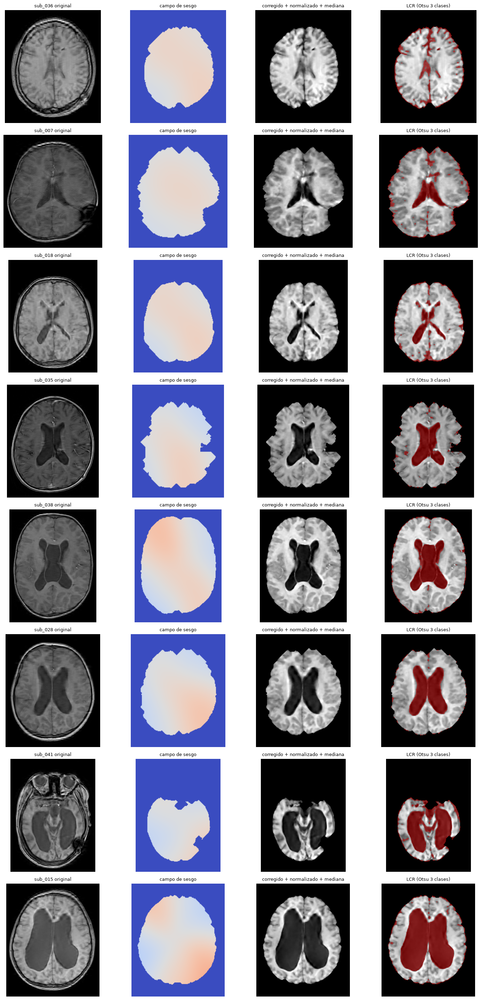

In [ ]:
fig, axes = plt.subplots(len(datos), 4, figsize=(15, 3.6 * len(datos)), squeeze=False)
for row, d in zip(axes, datos):
    p = preprocesar(d["img"], d["zooms"])
    k = int(np.argmax(d["g"].sum(axis=(0, 1))))
    sl = lambda a: np.rot90(a[:, :, k])
    row[0].imshow(sl(d["img"]), cmap="gray"); row[0].set_title(f"{d['subject']} original", fontsize=9)
    row[1].imshow(sl(p["campo"]), cmap="coolwarm", vmin=0.8, vmax=1.2); row[1].set_title("campo de sesgo", fontsize=9)
    row[2].imshow(sl(p["norm"]), cmap="gray", vmin=0, vmax=1); row[2].set_title("corregido + normalizado + mediana", fontsize=9)
    row[3].imshow(sl(p["norm"]), cmap="gray", vmin=0, vmax=1)
    row[3].contourf(sl(p["csf"]), levels=[0.5, 1.5], colors=["red"], alpha=0.4)
    row[3].set_title("LCR (Otsu 3 clases)", fontsize=9)
    for a in row:
        a.axis("off")
plt.tight_layout(); guardar("preprocesamiento"); plt.show()

## Ajuste de `Z_OFF_MM` y efecto de la corrección de sesgo

In [ ]:
def evaluar():
    d, e = [], []
    for x in datos:
        v, *_ = segmentar(x["img"], x["zooms"])
        ml = float(np.prod(x["zooms"])) / 1000
        d.append(dice(v, x["g"]))
        e.append(abs(v.sum() * ml - x["vol_gt"]) / x["vol_gt"] * 100)
    return np.nanmean(d), np.mean(e), d

filas = []
for zo in [-10, -5, 0, 5, 10]:
    Z_OFF_MM = zo
    dm, em, d = evaluar()
    filas.append({"Z_OFF_MM": zo, "dice_medio": dm, "error_vol_%": em, **{x["subject"]: v for x, v in zip(datos, d)}})
    print(f"Z_OFF_MM={zo:+d}: Dice {dm:.3f} | error vol {em:.0f}%")
barrido = pd.DataFrame(filas)
barrido.to_csv(FIG_DIR / "barrido_Z_OFF.csv", index=False)
Z_OFF_MM = int(barrido.loc[barrido.dice_medio.idxmax(), "Z_OFF_MM"])
print(barrido.drop(columns=['Z_OFF_MM']).round(2))
print("Z_OFF_MM =", Z_OFF_MM)

for b in [False, True]:
    BIAS = b
    dm, em, _ = evaluar()
    print(f"corrección de sesgo {'sí' if b else 'no'}: Dice {dm:.3f} | error vol {em:.0f}%")

Z_OFF_MM=-10: Dice 0.649 | error vol 53%
Z_OFF_MM=-5: Dice 0.648 | error vol 51%
Z_OFF_MM=+0: Dice 0.643 | error vol 49%
Z_OFF_MM=+5: Dice 0.639 | error vol 48%
Z_OFF_MM=+10: Dice 0.637 | error vol 45%
   dice_medio  error_vol_%  sub_036  sub_007  sub_018  sub_035  sub_038  \
0        0.65        52.91     0.21     0.35     0.59     0.89     0.70   
1        0.65        50.96     0.21     0.33     0.58     0.88     0.71   
2        0.64        49.16     0.21     0.32     0.56     0.86     0.72   
3        0.64        47.51     0.22     0.32     0.55     0.84     0.73   
4        0.64        45.38     0.22     0.32     0.55     0.82     0.75   

   sub_028  sub_041  sub_015  
0     0.87     0.72     0.87  
1     0.87     0.72     0.87  
2     0.87     0.72     0.88  
3     0.87     0.71     0.88  
4     0.86     0.70     0.87  
Z_OFF_MM = -10
corrección de sesgo no: Dice 0.649 | error vol 54%
corrección de sesgo sí: Dice 0.649 | error vol 53%


In [ ]:
BIAS = True
resultados = []
for x in datos:
    t0 = time.time()
    v, rama, est, p, pasos = segmentar(x["img"], x["zooms"])
    ml = float(np.prod(x["zooms"])) / 1000
    resultados.append({**x, "pred": v, "pasos": pasos, "rama": rama, "est": est,
                       "dice": dice(v, x["g"]), "vol_pred": v.sum() * ml})
    print(f"{x['subject']} ({time.time() - t0:.0f}s) [{rama}] Dice {resultados[-1]['dice']:.3f} | "
          f"{resultados[-1]['vol_pred']:.0f} vs {x['vol_gt']:.0f} mL")

tabla = pd.DataFrame([{"subject": r["subject"], "rama": r["rama"], "vol_gt": r["vol_gt"], "vol_pred": r["vol_pred"],
                       "dice": r["dice"], "error_vol_%": (r["vol_pred"] - r["vol_gt"]) / r["vol_gt"] * 100,
                       **{f"dice_{k}": dice(r["pasos"][k], r["g"]) for k in r["pasos"]}} for r in resultados])
tabla.to_csv(FIG_DIR / "tabla_final.csv", index=False)
display(tabla.round(2))
print(f"Dice medio {tabla.dice.mean():.3f} | error vol abs medio {tabla['error_vol_%'].abs().mean():.1f}%")

sub_036 (30s) [pequeño] Dice 0.205 | 30 vs 10 mL
sub_007 (24s) [pequeño] Dice 0.348 | 21 vs 15 mL
sub_018 (28s) [pequeño] Dice 0.589 | 18 vs 26 mL
sub_035 (27s) [encerrado] Dice 0.888 | 60 vs 65 mL
sub_038 (34s) [encerrado] Dice 0.702 | 154 vs 89 mL
sub_028 (26s) [encerrado] Dice 0.871 | 126 vs 127 mL
sub_041 (25s) [encerrado] Dice 0.716 | 286 vs 173 mL
sub_015 (35s) [encerrado] Dice 0.872 | 475 vs 386 mL


,subject,rama,vol_gt,vol_pred,dice,error_vol_%,dice_inicial,dice_areas,dice_watershed,dice_forma,dice_final
0,sub_036,pequeño,10.42,29.69,0.21,185.07,0.17,0.26,0.21,0.21,0.21
1,sub_007,pequeño,15.35,21.40,0.35,39.44,0.38,0.30,0.35,0.34,0.35
2,sub_018,pequeño,26.00,18.37,0.59,-29.34,0.46,0.55,0.58,0.59,0.59
3,sub_035,encerrado,65.22,60.37,0.89,-7.43,0.86,0.86,0.87,0.87,0.89
4,sub_038,encerrado,88.88,153.98,0.70,73.24,0.66,0.66,0.66,0.66,0.70
5,sub_028,encerrado,126.64,126.23,0.87,-0.32,0.84,0.85,0.85,0.85,0.87
6,sub_041,encerrado,173.15,286.27,0.72,65.34,0.73,0.74,0.72,0.70,0.72
7,sub_015,encerrado,385.69,474.77,0.87,23.10,0.86,0.86,0.85,0.85,0.87


Dice medio 0.649 | error vol abs medio 52.9%


## Pasos del pipeline por caso (axial)

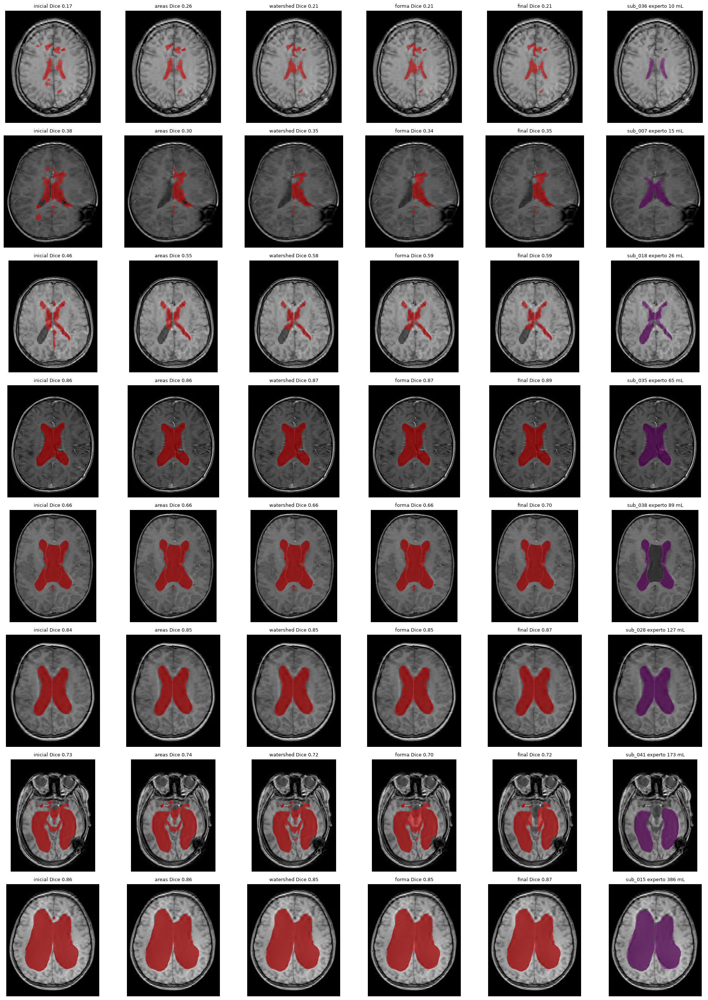

In [ ]:
pasos_n = ["inicial", "areas", "watershed", "forma", "final"]
fig, axes = plt.subplots(len(resultados), 6, figsize=(20, 3.4 * len(resultados)), squeeze=False)
for row, r in zip(axes, resultados):
    k = int(np.argmax(r["g"].sum(axis=(0, 1))))
    sl = lambda a: np.rot90(a[:, :, k])
    for ax, (m, t, c) in zip(row, [(r["pasos"][p], p, "red") for p in pasos_n] + [(r["g"], "experto", "purple")]):
        ax.imshow(sl(r["img"]), cmap="gray")
        ax.contourf(sl(m), levels=[0.5, 1.5], colors=[c], alpha=0.45)
        ax.set_title(f"{t} Dice {dice(m, r['g']):.2f}" if t != "experto" else f"{r['subject']} experto {r['vol_gt']:.0f} mL", fontsize=9)
        ax.axis("off")
plt.tight_layout(); guardar("pasos_axial"); plt.show()

## Final vs experto en 3 planos

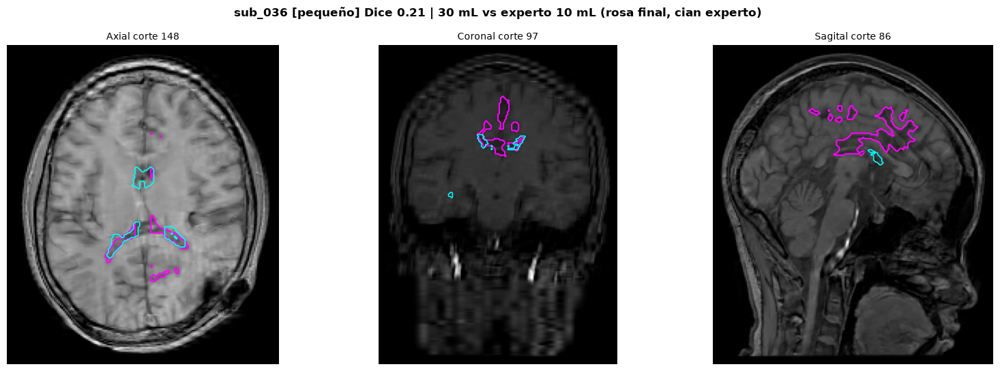

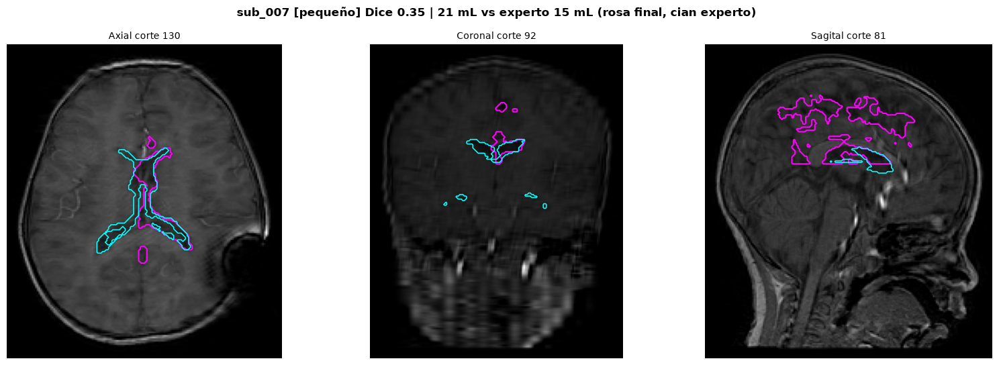

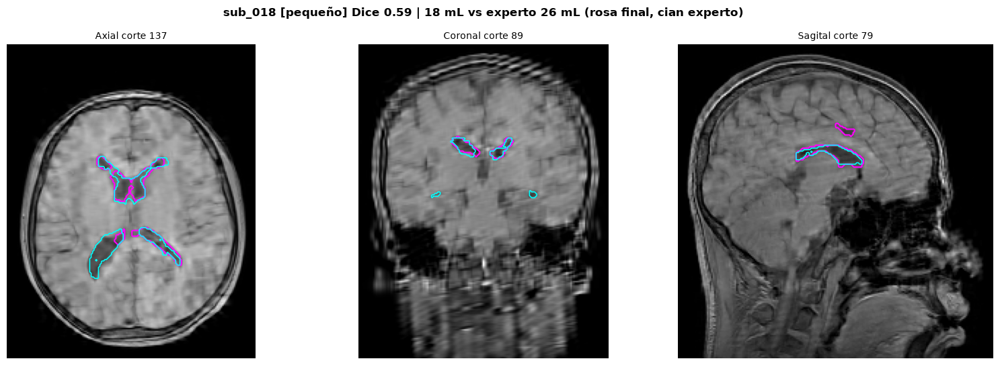

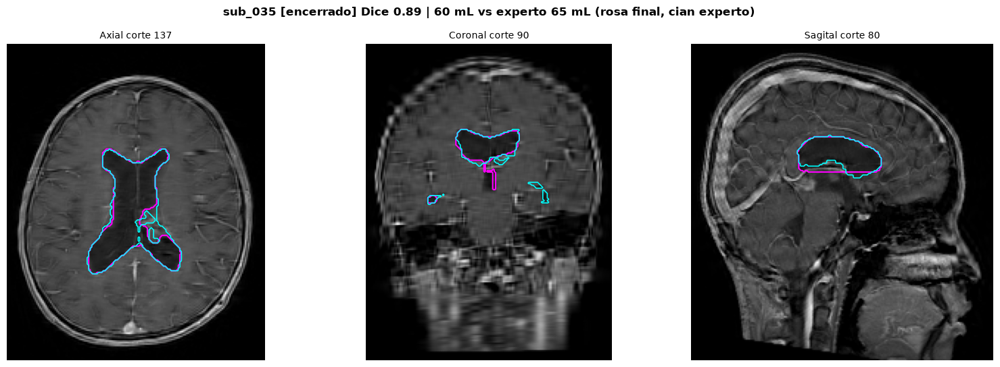

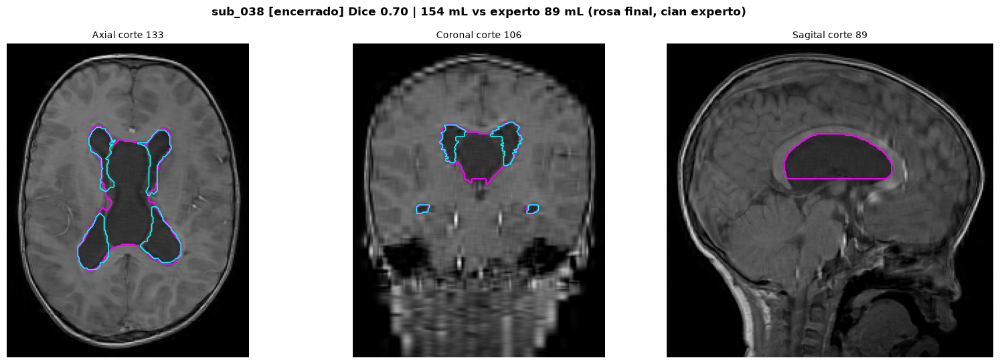

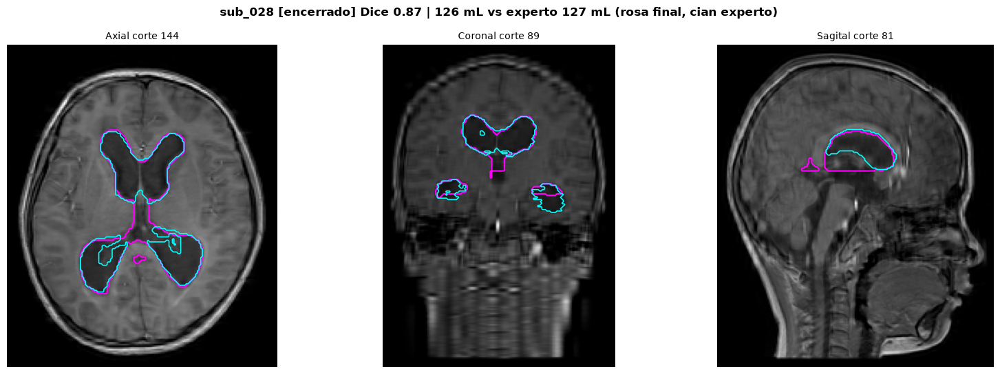

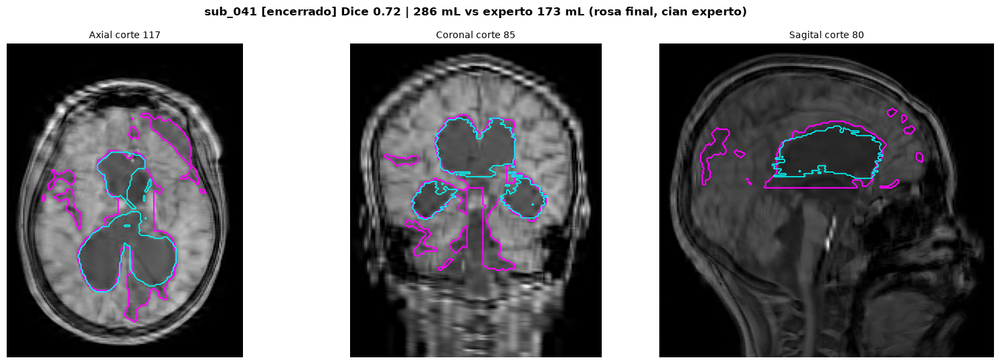

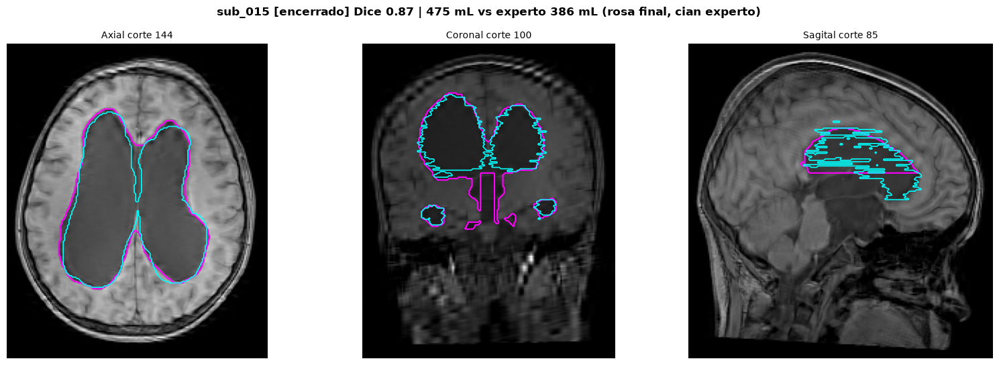

In [ ]:
def ver_caso(r):
    c = [int(round(x)) for x in ndi.center_of_mass(r["g"])]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
    for ax, (nm, axis) in zip(axes, [("Axial", 2), ("Coronal", 1), ("Sagital", 0)]):
        take = lambda a: np.rot90(np.take(a, c[axis], axis=axis))
        ax.imshow(take(r["img"]), cmap="gray")
        ax.contour(take(r["pred"]), levels=[0.5], colors="magenta", linewidths=1.5)
        ax.contour(take(r["g"]), levels=[0.5], colors="cyan", linewidths=1.2)
        ax.set_title(f"{nm} corte {c[axis]}", fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{r['subject']} [{r['rama']}] Dice {r['dice']:.2f} | {r['vol_pred']:.0f} mL vs experto {r['vol_gt']:.0f} mL (rosa final, cian experto)",
                 fontsize=12, weight="bold")
    plt.tight_layout(); guardar(f"planos_{r['subject']}"); plt.show()

for r in resultados:
    ver_caso(r)

## Vista 3D

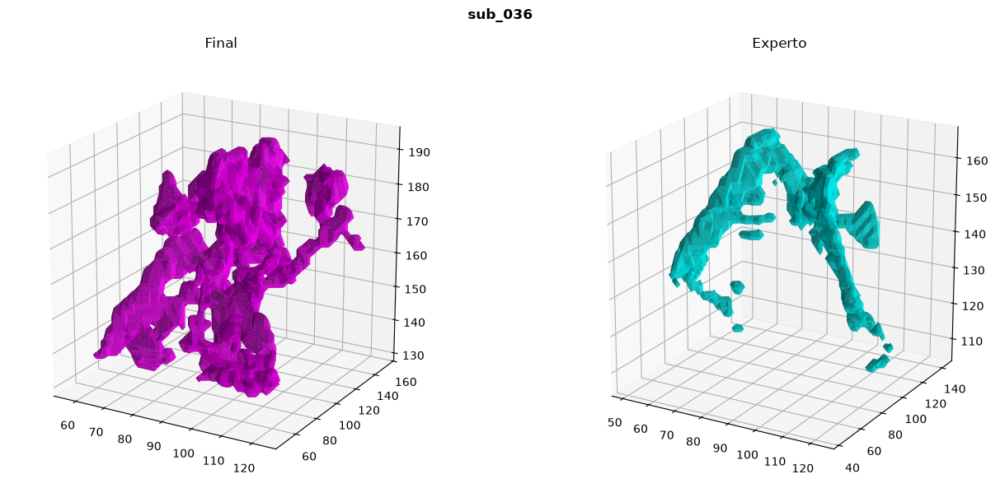

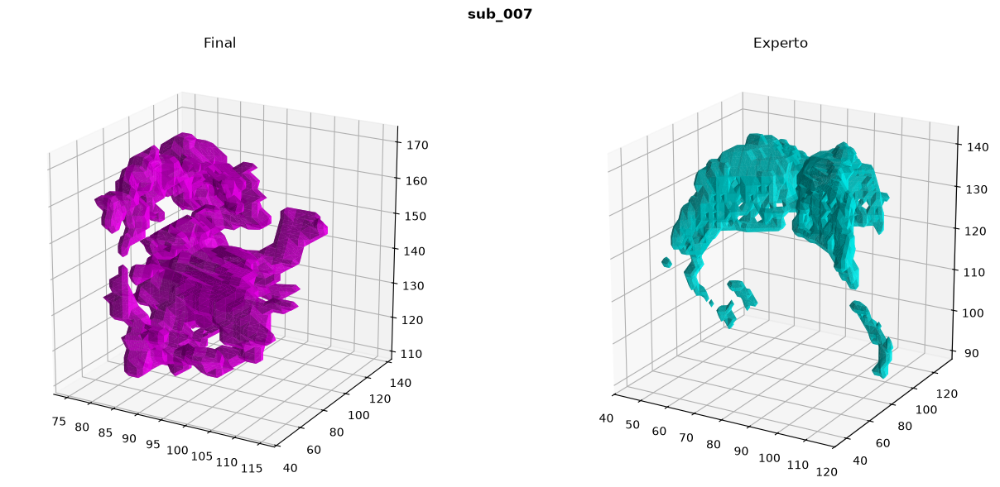

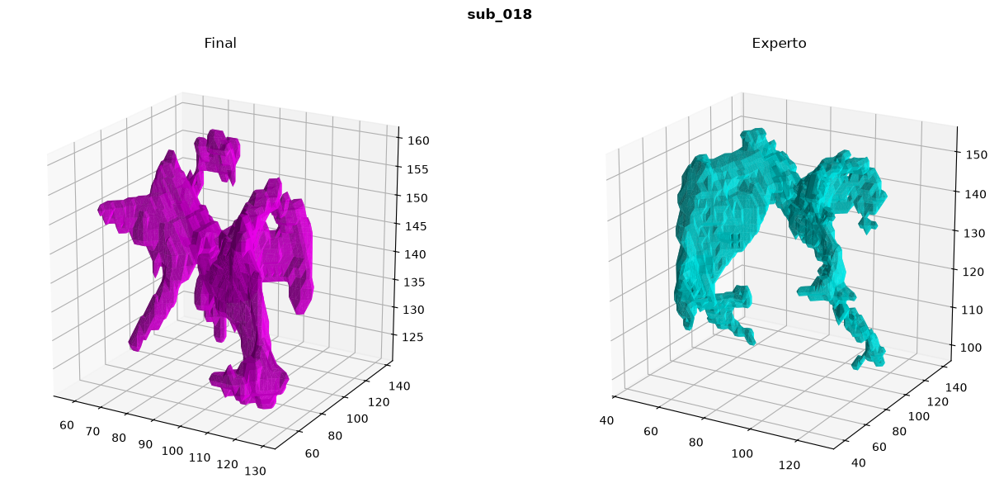

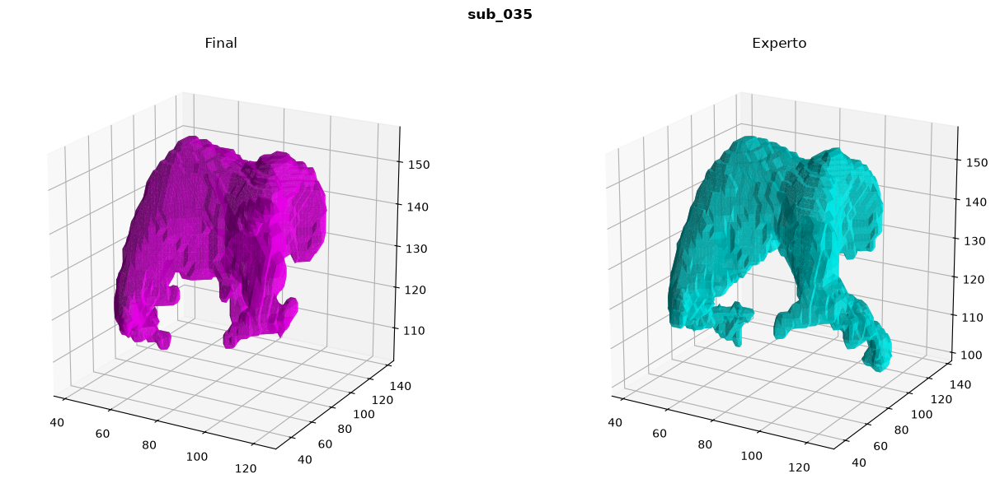

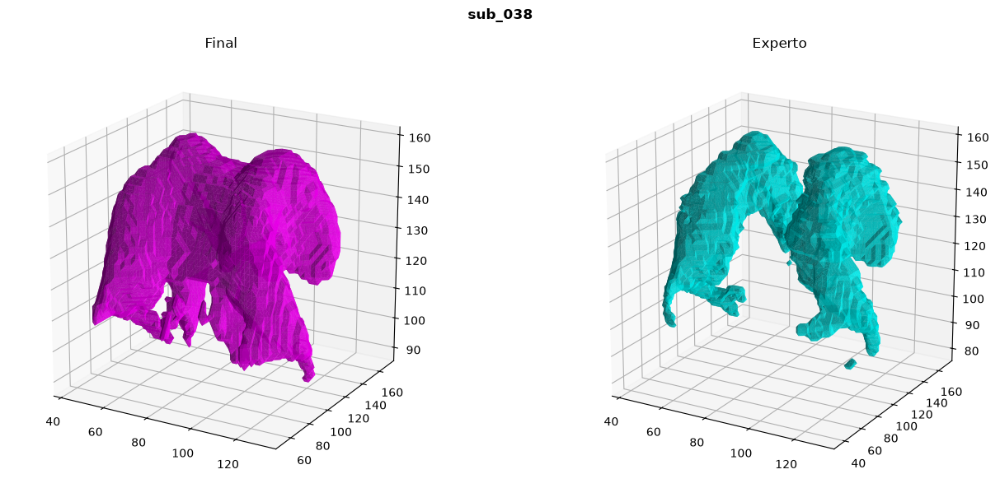

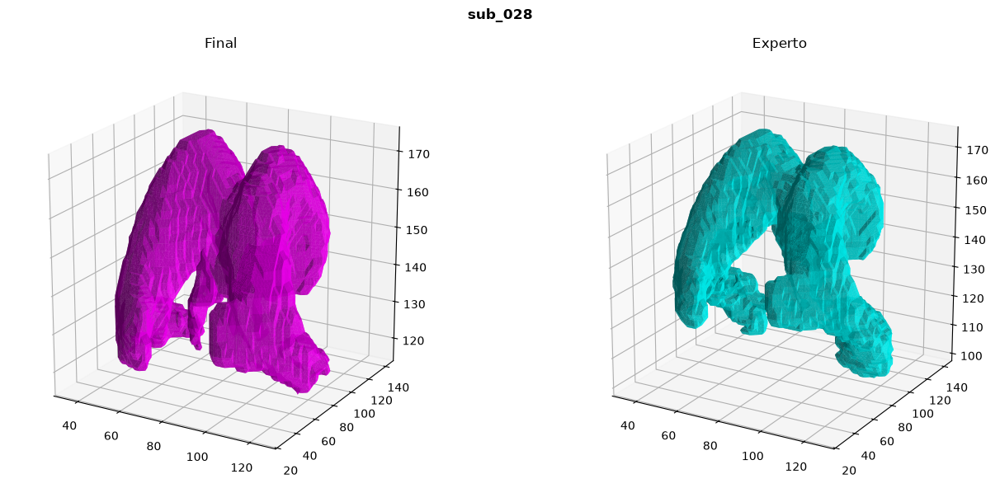

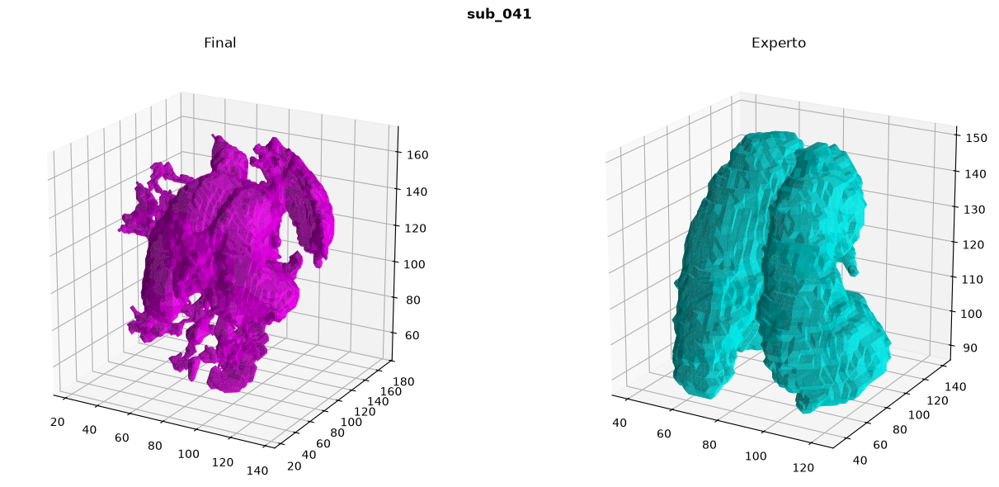

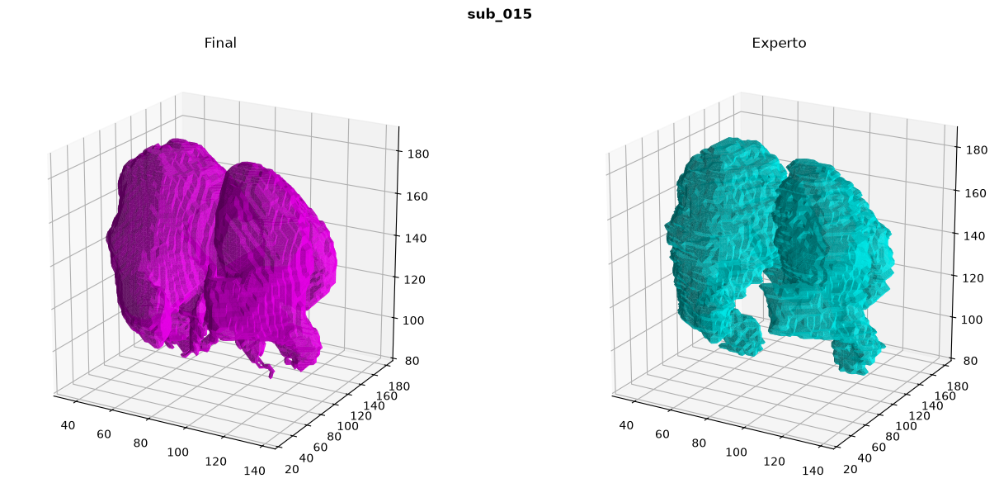

In [ ]:
from skimage.measure import marching_cubes

def ver_3d(r, paso=2):
    fig = plt.figure(figsize=(14, 6))
    for k, (m, t, col) in enumerate([(r["pred"], "Final", "magenta"), (r["g"], "Experto", "cyan")]):
        ax = fig.add_subplot(1, 2, k + 1, projection="3d")
        if m.sum() > 0:
            verts, faces, _, _ = marching_cubes(m.astype(np.uint8), 0.5, spacing=r["zooms"], step_size=paso)
            ax.plot_trisurf(verts[:, 0], verts[:, 1], faces, verts[:, 2], color=col, alpha=0.8, linewidth=0)
        ax.set_title(t)
        ax.view_init(elev=20, azim=-60)
        ax.set_box_aspect((1, 1, 1))
    fig.suptitle(r["subject"], fontsize=12, weight="bold")
    plt.tight_layout(); guardar(f"3d_{r['subject']}"); plt.show()

for r in resultados:
    ver_3d(r)

## Resumen

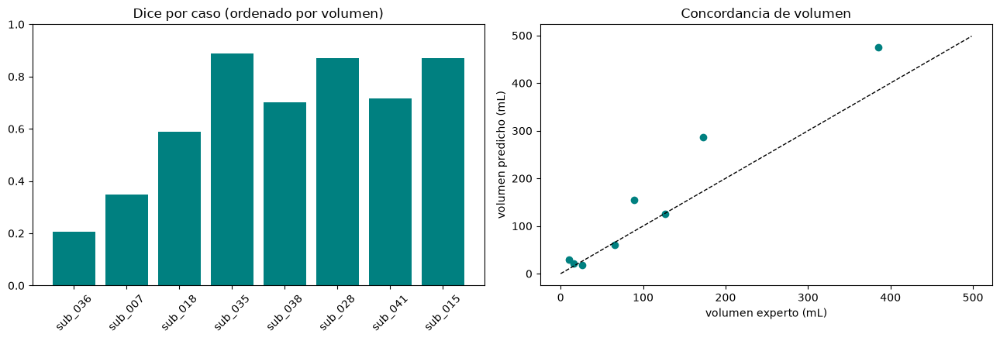

Archivos en C:\Users\Usuario\Desktop\Vida_Academica\2026-II\FIB\hykid\outputs\figuras_03


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(tabla.subject, tabla.dice, color="teal")
ax[0].set_ylim(0, 1); ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Dice por caso (ordenado por volumen)")
lim = [0, max(tabla.vol_gt.max(), tabla.vol_pred.max()) * 1.05]
ax[1].scatter(tabla.vol_gt, tabla.vol_pred, color="teal")
ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlabel("volumen experto (mL)"); ax[1].set_ylabel("volumen predicho (mL)"); ax[1].set_title("Concordancia de volumen")
plt.tight_layout(); guardar("resumen"); plt.show()
print("Archivos en", FIG_DIR)

## Visor interactivo

In [ ]:
from ipywidgets import interact, IntSlider, Dropdown

def visor(caso, plano, corte):
    r = next(x for x in resultados if x["subject"] == caso)
    axis = {"Axial": 2, "Coronal": 1, "Sagital": 0}[plano]
    corte = min(corte, r["img"].shape[axis] - 1)
    take = lambda a: np.rot90(np.take(a, corte, axis=axis))
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.imshow(take(r["img"]), cmap="gray")
    ax.contour(take(r["pred"]), levels=[0.5], colors="magenta", linewidths=1.5)
    ax.contour(take(r["g"]), levels=[0.5], colors="cyan", linewidths=1.2)
    ax.set_title(f"{caso} {plano} {corte}")
    ax.axis("off")
    plt.show()

interact(visor, caso=Dropdown(options=[r["subject"] for r in resultados]),
         plano=Dropdown(options=["Axial", "Coronal", "Sagital"]), corte=IntSlider(80, 0, 255))

interactive(children=(Dropdown(description='caso', options=('sub_036', 'sub_007', 'sub_018', 'sub_035', 'sub_0…

<function __main__.visor(caso, plano, corte)>

## Evaluación en todos los casos vs SynthSeg

Mismo pipeline y parámetros, sin ajustar. SynthSeg: etiquetas 4, 5, 43, 44 (ventrículos laterales e inferiores).
Rangos de volumen experto: pequeño < 30 mL, mediano 30 a 150 mL, grande > 150 mL.

In [ ]:
SS_VENT = [4, 5, 43, 44]
BIAS = True
filas = []
for s in scans:
    t0 = time.time()
    img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
    gt, _ = load_seg(s / "segmentation" / "gt.nii.gz")
    ss_path = s / "segmentation" / "synthseg.nii.gz"
    box = crop_box(img)
    img, gt = img[box], gt[box]
    g = gt == 4
    ml = float(np.prod(zooms)) / 1000
    v, rama, *_ = segmentar(img, zooms)
    fila = {"subject": s.parent.name, "scan": s.name, "rama": rama, "vol_gt": g.sum() * ml,
            "vol_clasico": v.sum() * ml, "dice_clasico": dice(v, g)}
    if ss_path.exists():
        ss = load_seg(ss_path)[0][box]
        if ss.shape == g.shape:
            a = np.isin(ss, SS_VENT)
            fila.update(vol_synthseg=a.sum() * ml, dice_synthseg=dice(a, g))
    filas.append(fila)
    print(f"{s.parent.name}/{s.name} ({time.time() - t0:.0f}s): clásico {fila['dice_clasico']:.2f} | SynthSeg {fila.get('dice_synthseg', np.nan):.2f}")

todos = pd.DataFrame(filas)
for m in ["clasico", "synthseg"]:
    if f"vol_{m}" in todos:
        todos[f"err_{m}_%"] = (todos[f"vol_{m}"] - todos.vol_gt) / todos.vol_gt * 100
todos["rango"] = pd.cut(todos.vol_gt, [0, 30, 150, np.inf], labels=["pequeño", "mediano", "grande"])
todos.to_csv(FIG_DIR / "evaluacion_todos.csv", index=False)

sub_001/scan_01 (36s): clásico 0.67 | SynthSeg 0.90
sub_003/scan_01 (29s): clásico 0.65 | SynthSeg 0.98
sub_004/scan_01 (31s): clásico 0.92 | SynthSeg 0.84
sub_005/scan_01 (23s): clásico 0.86 | SynthSeg 0.91
sub_006/scan_01 (34s): clásico 0.55 | SynthSeg 0.56
sub_007/scan_01 (29s): clásico 0.35 | SynthSeg 0.86
sub_009/scan_01 (13s): clásico 0.66 | SynthSeg 0.96
sub_010/scan_01 (8s): clásico 0.88 | SynthSeg 0.87
sub_011/scan_01 (20s): clásico 0.00 | SynthSeg 0.80
sub_012/scan_01 (29s): clásico 0.93 | SynthSeg 0.72
sub_013/scan_01 (32s): clásico 0.06 | SynthSeg 0.89
sub_015/scan_01 (37s): clásico 0.87 | SynthSeg 0.06
sub_016/scan_01 (34s): clásico 0.86 | SynthSeg 0.89
sub_017/scan_01 (28s): clásico 0.91 | SynthSeg 0.84
sub_018/scan_01 (35s): clásico 0.59 | SynthSeg 0.74
sub_019/scan_01 (28s): clásico 0.56 | SynthSeg 0.93
sub_019/scan_02 (35s): clásico 0.46 | SynthSeg 0.93
sub_020/scan_01 (24s): clásico 0.84 | SynthSeg 0.96
sub_021/scan_01 (32s): clásico 0.26 | SynthSeg 0.90
sub_022/scan_

In [ ]:
def resumen_grupo(df):
    out = {"n": len(df)}
    for m in ["clasico", "synthseg"]:
        if f"dice_{m}" in df:
            out[f"dice_{m}_media"] = df[f"dice_{m}"].mean()
            out[f"dice_{m}_mediana"] = df[f"dice_{m}"].median()
            out[f"err_{m}_abs_mediana_%"] = df[f"err_{m}_%"].abs().median()
    return pd.Series(out)

res = todos.groupby("rango", observed=True).apply(resumen_grupo)
res.loc["total"] = resumen_grupo(todos)
res.to_csv(FIG_DIR / "resumen_por_rango.csv")
display(res.round(3))

,n,dice_clasico_media,dice_clasico_mediana,err_clasico_abs_mediana_%,dice_synthseg_media,dice_synthseg_mediana,err_synthseg_abs_mediana_%
rango,,,,,,,
pequeño,14.0,0.390,0.466,68.479,0.886,0.897,5.756
mediano,20.0,0.814,0.855,19.548,0.887,0.952,5.006
grande,11.0,0.752,0.878,12.388,0.735,0.839,25.601
total,45.0,0.667,0.781,29.506,0.849,0.903,7.998


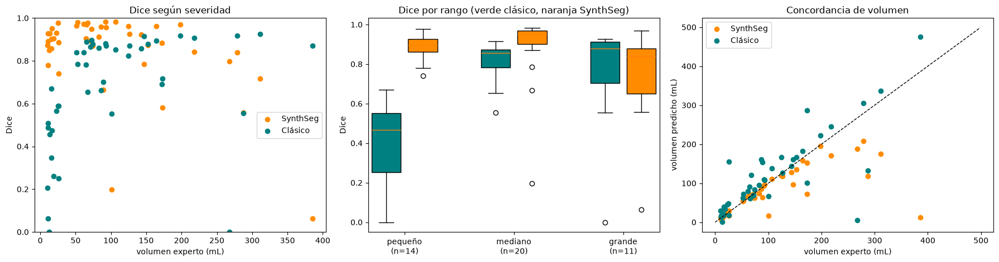

Peores casos del método clásico:


,subject,rama,vol_gt,vol_clasico,dice_clasico,dice_synthseg
8,sub_011,pequeño,267.59,5.45,0.00,0.80
23,sub_026,encerrado,12.73,0.89,0.00,0.85
10,sub_013,pequeño,11.15,14.36,0.06,0.89
31,sub_036,pequeño,10.42,29.69,0.21,0.87
41,sub_045,encerrado,26.08,155.71,0.25,0.89
18,sub_021,pequeño,18.45,33.32,0.26,0.90


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(todos.vol_gt, todos.dice_synthseg, color="darkorange", label="SynthSeg")
ax[0].scatter(todos.vol_gt, todos.dice_clasico, color="teal", label="Clásico")
ax[0].set_xlabel("volumen experto (mL)"); ax[0].set_ylabel("Dice"); ax[0].set_ylim(0, 1); ax[0].legend()
ax[0].set_title("Dice según severidad")

orden = ["pequeño", "mediano", "grande"]
datos_box, pos, cols = [], [], []
for i, r in enumerate(orden):
    sub = todos[todos.rango == r]
    datos_box += [sub.dice_clasico.dropna(), sub.dice_synthseg.dropna()]
    pos += [i * 3, i * 3 + 1]
    cols += ["teal", "darkorange"]
bp = ax[1].boxplot(datos_box, positions=pos, widths=0.8, patch_artist=True)
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
ax[1].set_xticks([0.5, 3.5, 6.5]); ax[1].set_xticklabels([f"{r}\n(n={(todos.rango == r).sum()})" for r in orden])
ax[1].set_ylabel("Dice"); ax[1].set_title("Dice por rango (verde clásico, naranja SynthSeg)")

lim = [0, max(todos.vol_gt.max(), todos.vol_clasico.max(), todos.vol_synthseg.max()) * 1.05]
ax[2].scatter(todos.vol_gt, todos.vol_synthseg, color="darkorange", label="SynthSeg")
ax[2].scatter(todos.vol_gt, todos.vol_clasico, color="teal", label="Clásico")
ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("volumen experto (mL)"); ax[2].set_ylabel("volumen predicho (mL)"); ax[2].legend()
ax[2].set_title("Concordancia de volumen")
plt.tight_layout(); guardar("evaluacion_todos"); plt.show()

print("Peores casos del método clásico:")
display(todos.sort_values("dice_clasico").head(6)[["subject", "rama", "vol_gt", "vol_clasico", "dice_clasico", "dice_synthseg"]].round(2))